<a href="https://colab.research.google.com/github/Wrdone/MH/blob/main/%D0%9B%D0%A03_%D0%9B%D1%83%D0%BA'%D1%8F%D0%BD_10.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Лабораторна робота 3. Машинне навчання
## Регресія: прогнозування вартості нерухомості

**Мета роботи:** виконати первинний аналіз даних, побудувати кілька моделей регресії, оцінити їхню якість та виконати підбір гіперпараметрів для моделі Random Forest.

### Датасет
Можна використати один із двох способів завантаження даних:

1. Завантажити файл з Google Drive:
https://drive.google.com/file/d/1u_-3X05st6uvrgQB1qNLyE8a7QjTJjvd/view?usp=sharing

2. Завантажити датасет з Kaggle:
https://www.kaggle.com/datasets/prokshitha/home-value-insights

> Посилання та вміст датасету на зовнішніх платформах можуть змінюватися.

## 1. Імпорт бібліотек
Імпортуйте бібліотеки, необхідні для роботи з даними, візуалізації та числових обчислень.

In [ ]:
# Ваш код:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
#Налашт. стилю графіків
sns.set_theme(style="whitegrid")


## 2. Завантаження даних
Завантажте файл двома способами.

### Варіант 1. Завантаження файлу з комп’ютера
Завантажте CSV-файл у середовище Colab.

In [ ]:
# Ваш код:
df = pd.read_csv('house_price_regression_dataset.csv')


### Варіант 2. Завантаження датасету з Kaggle
Завантажте датасет безпосередньо з Kaggle та прочитайте CSV-файл у DataFrame `df`.

In [ ]:
# Ваш код:
df = pd.read_csv('house_price_regression_dataset_K.csv')


## 3. Опис ознак датасету

- **Square_Footage** — загальна житлова площа будинку.
- **Num_Bedrooms** — кількість спалень.
- **Num_Bathrooms** — кількість ванних кімнат.
- **Year_Built** — рік побудови будинку.
- **Lot_Size** — розмір земельної ділянки.
- **Garage_Size** — розмір гаража або кількість паркомісць.
- **Neighborhood_Quality** — оцінка якості району.
- **House_Price** — ціна будинку, цільова змінна.

## 4. Первинний аналіз даних

### Завдання 1. Перегляд даних
Виведіть перші рядки датасету та перегляньте його структуру.

In [ ]:
# Ваш код:
display(df.head())
display(df.info())


,Square_Footage,Num_Bedrooms,Num_Bathrooms,Year_Built,Lot_Size,Garage_Size,Neighborhood_Quality,House_Price
0,1360,2,1,1981,0.599637,0,5,2.623829e+05
1,4272,3,3,2016,4.753014,1,6,9.852609e+05
2,3592,1,2,2016,3.634823,0,9,7.779774e+05
3,966,1,2,1977,2.730667,1,8,2.296989e+05
4,4926,2,1,1993,4.699073,0,8,1.041741e+06


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 8 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   Square_Footage        1000 non-null   int64  
 1   Num_Bedrooms          1000 non-null   int64  
 2   Num_Bathrooms         1000 non-null   int64  
 3   Year_Built            1000 non-null   int64  
 4   Lot_Size              1000 non-null   float64
 5   Garage_Size           1000 non-null   int64  
 6   Neighborhood_Quality  1000 non-null   int64  
 7   House_Price           1000 non-null   float64
dtypes: float64(2), int64(6)
memory usage: 62.6 KB


None

### Завдання 2. Перевірка дублікатів
Визначте кількість дубльованих рядків.

In [ ]:
# Ваш код:
print("Кількість дублікатів:", df.duplicated().sum())


Кількість дублікатів: 0


### Завдання 3. Перевірка пропущених значень
Визначте кількість пропущених значень у кожному стовпці.

In [ ]:
# Ваш код:
print("Пропущені значення:\n", df.isnull().sum())


Пропущені значення:
 Square_Footage          0
Num_Bedrooms            0
Num_Bathrooms           0
Year_Built              0
Lot_Size                0
Garage_Size             0
Neighborhood_Quality    0
House_Price             0
dtype: int64


### Завдання 4. Описова статистика
Виведіть основні статистичні характеристики числових ознак.

In [ ]:
# Ваш код:
display(df.describe())


,Square_Footage,Num_Bedrooms,Num_Bathrooms,Year_Built,Lot_Size,Garage_Size,Neighborhood_Quality,House_Price
count,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1.000000e+03
mean,2815.422000,2.990000,1.973000,1986.550000,2.778087,1.022000,5.615000,6.188610e+05
std,1255.514921,1.427564,0.820332,20.632916,1.297903,0.814973,2.887059,2.535681e+05
min,503.000000,1.000000,1.000000,1950.000000,0.506058,0.000000,1.000000,1.116269e+05
25%,1749.500000,2.000000,1.000000,1969.000000,1.665946,0.000000,3.000000,4.016482e+05
50%,2862.500000,3.000000,2.000000,1986.000000,2.809740,1.000000,6.000000,6.282673e+05
75%,3849.500000,4.000000,3.000000,2004.250000,3.923317,2.000000,8.000000,8.271413e+05
max,4999.000000,5.000000,3.000000,2022.000000,4.989303,2.000000,10.000000,1.108237e+06


## 5. Аналіз окремих ознак

### Завдання 5. Ознака `Neighborhood_Quality`
Виведіть частоти значень ознаки `Neighborhood_Quality`.

In [ ]:
# Ваш код:
print(df['Neighborhood_Quality'].value_counts())


Neighborhood_Quality
10    123
5     109
2     105
7     102
6     101
4      99
8      97
1      91
9      88
3      85
Name: count, dtype: int64


### Завдання 6. Візуалізація `Neighborhood_Quality`
Побудуйте діаграму розподілу значень цієї ознаки.

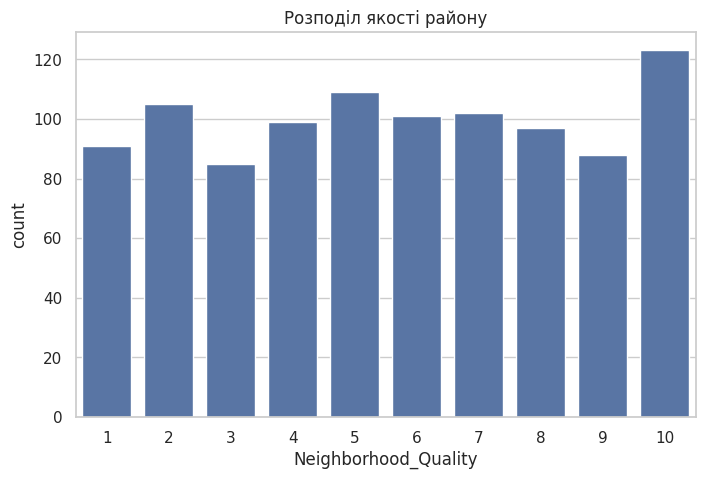

In [ ]:
# Ваш код:
plt.figure(figsize=(8, 5))
sns.countplot(data=df, x='Neighborhood_Quality')
plt.title('Розподіл якості району')
plt.show()


### Завдання 7. Ознака `Num_Bathrooms`
Виведіть частоти значень кількості ванних кімнат.

In [ ]:
# Ваш код:
print(df['Num_Bathrooms'].value_counts())


Num_Bathrooms
1    350
2    327
3    323
Name: count, dtype: int64


### Завдання 8. Візуалізація `Num_Bathrooms`
Побудуйте діаграму розподілу кількості ванних кімнат.

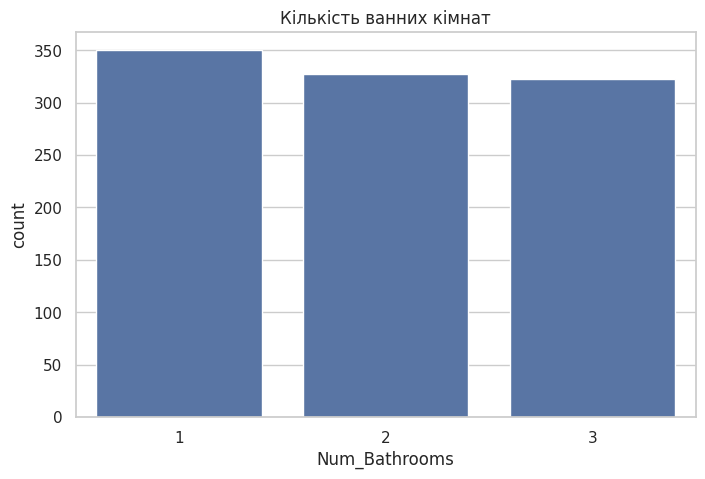

In [ ]:
# Ваш код:
plt.figure(figsize=(8, 5))
sns.countplot(data=df, x='Num_Bathrooms')
plt.title('Кількість ванних кімнат')
plt.show()


### Додаткове завдання
За потреби побудуйте попарні графіки числових ознак і коротко проаналізуйте можливі залежності.

In [ ]:
# Ваш код:
# Побудуйте pairplot або іншу попарну візуалізацію.





## 6. Кореляційний аналіз

### Завдання 9. Матриця кореляції
Побудуйте кореляційну матрицю для числових ознак та відобразіть її у вигляді теплової карти.

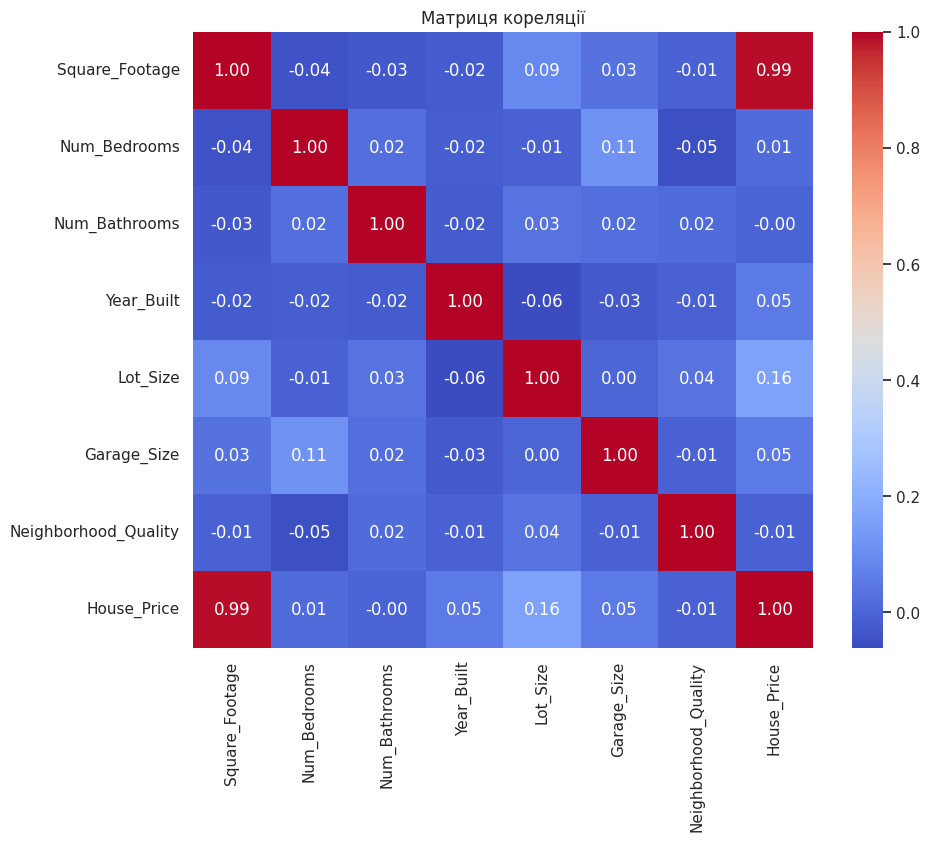

In [ ]:
# Ваш код:
numeric_df = df.select_dtypes(include=[np.number])
plt.figure(figsize=(10, 8))
sns.heatmap(numeric_df.corr(), annot=True, cmap='coolwarm', fmt=".2f")
plt.title('Матриця кореляції')
plt.show()


### Завдання 10. Кореляція з цільовою змінною
Виведіть кореляцію кожної ознаки з `House_Price`, відсортувавши значення за спаданням.

In [ ]:
# Ваш код:
print(numeric_df.corr()['House_Price'].sort_values(ascending=False))


House_Price             1.000000
Square_Footage          0.991261
Lot_Size                0.160412
Garage_Size             0.052133
Year_Built              0.051967
Num_Bedrooms            0.014633
Num_Bathrooms          -0.001862
Neighborhood_Quality   -0.007770
Name: House_Price, dtype: float64


## 7. Побудова моделей регресії

### Завдання 11. Імпорт інструментів Scikit-learn
Імпортуйте засоби для:
- поділу вибірки;
- масштабування ознак;
- побудови Linear Regression, Ridge, Lasso, Random Forest та Gradient Boosting;
- створення Pipeline;
- обчислення R², MAE та MSE.

In [ ]:
# Ваш код:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error


### Завдання 12. Формування `X` і `y`
Відокремте ознаки від цільової змінної `House_Price`.

In [ ]:
# Ваш код:
X = pd.get_dummies(df.drop('House_Price', axis=1), drop_first=True)
y = df['House_Price']


### Завдання 13. Поділ даних
Поділіть дані на навчальну і тестову вибірки у співвідношенні 80/20. Для відтворюваності використайте `random_state=42`.

In [ ]:
# Ваш код:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)



### Завдання 14. Створення моделей
Створіть п’ять моделей:
1. Linear Regression;
2. Ridge;
3. Lasso;
4. Random Forest Regressor;
5. Gradient Boosting Regressor.

Для лінійних моделей використайте `Pipeline` зі `StandardScaler`. Для деревоподібних моделей масштабування не потрібне.

In [ ]:
# Ваш код:
models = {
    'Linear Regression': Pipeline([('scaler', StandardScaler()), ('lr', LinearRegression())]),
    'Ridge': Pipeline([('scaler', StandardScaler()), ('ridge', Ridge())]),
    'Lasso': Pipeline([('scaler', StandardScaler()), ('lasso', Lasso())]),
    'Random Forest': RandomForestRegressor(random_state=42),
    'Gradient Boosting': GradientBoostingRegressor(random_state=42)
}


### Завдання 15. Навчання та оцінювання моделей
Для кожної моделі:
- виконайте навчання на тренувальній вибірці;
- отримайте прогноз для тестової вибірки;
- обчисліть `R²`, `MAE`, `MSE`;
- збережіть результати для подальшого порівняння.

In [ ]:
# Ваш код:
results = {}
for name, model in models.items():
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)

    r2 = r2_score(y_test, y_pred)
    mae = mean_absolute_error(y_test, y_pred)
    mse = mean_squared_error(y_test, y_pred)

    results[name] = {'R2': r2, 'MAE': mae, 'MSE': mse, 'Predictions': y_pred}
    print(f"--- {name} ---")
    print(f"R²: {r2:.4f} | MAE: {mae:.2f} | MSE: {mse:.2f}\n")


--- Linear Regression ---
R²: 0.9984 | MAE: 8174.58 | MSE: 101434798.51

--- Ridge ---
R²: 0.9984 | MAE: 8241.59 | MSE: 102480990.01

--- Lasso ---
R²: 0.9984 | MAE: 8174.75 | MSE: 101436558.18

--- Random Forest ---
R²: 0.9939 | MAE: 16114.29 | MSE: 394131747.45

--- Gradient Boosting ---
R²: 0.9965 | MAE: 12305.22 | MSE: 224965597.85



### Завдання 16. Графічне порівняння прогнозів
Для кожної моделі побудуйте графік **фактичні значення vs прогнозовані значення**. Додайте лінію ідеального прогнозу.

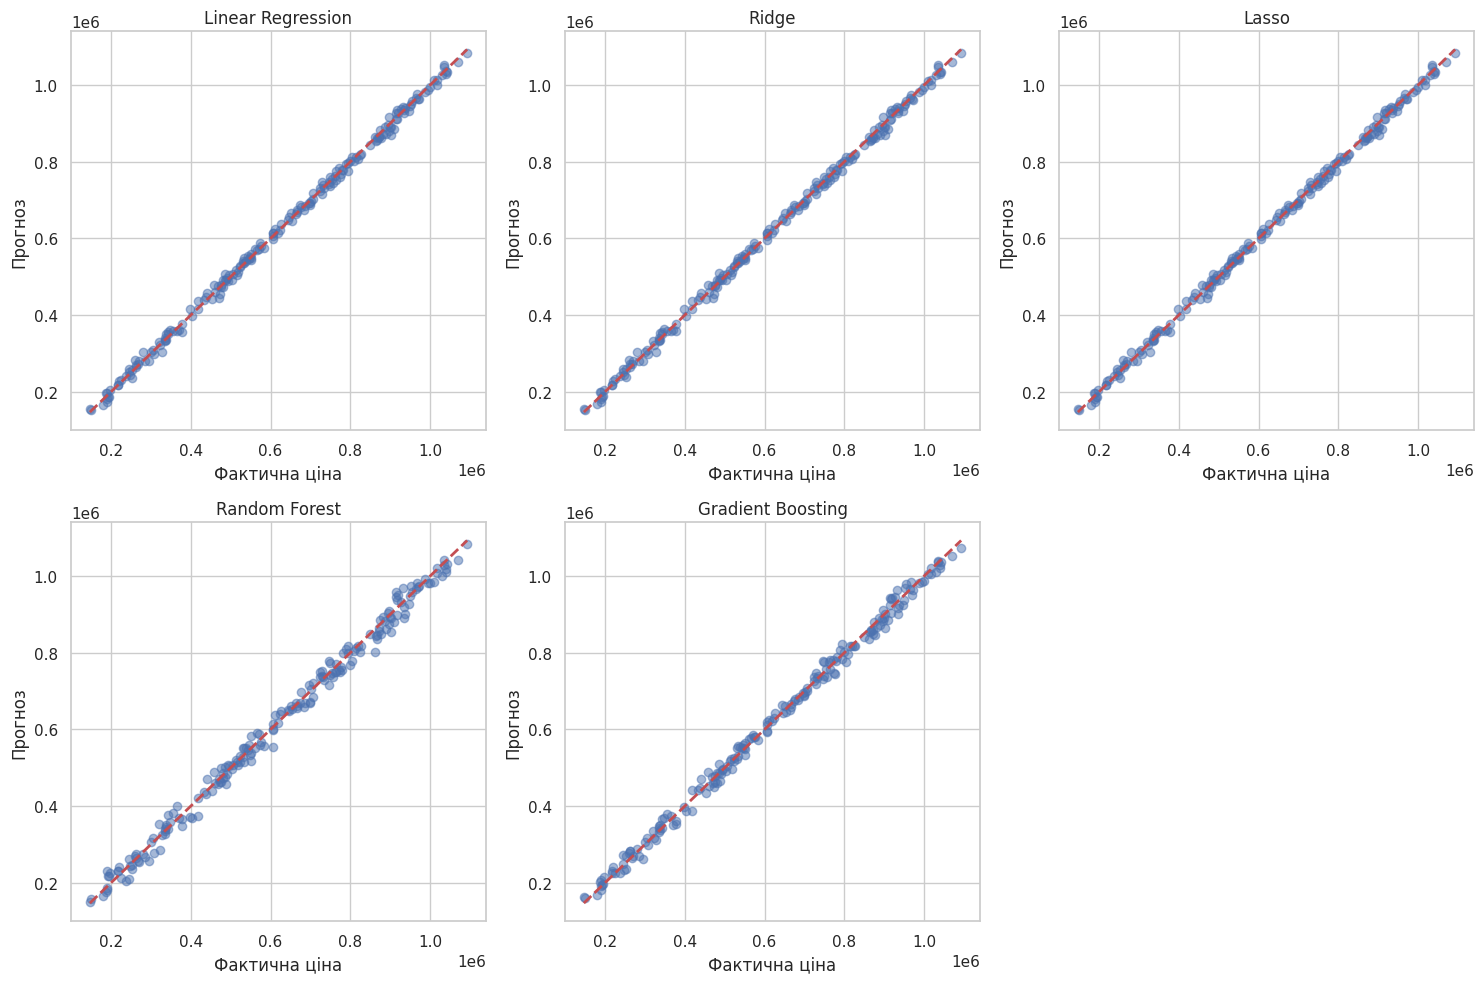

In [ ]:
# Ваш код:
plt.figure(figsize=(15, 10))
for i, (name, res) in enumerate(results.items(), 1):
    plt.subplot(2, 3, i)
    plt.scatter(y_test, res['Predictions'], alpha=0.5)
    plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', lw=2)
    plt.title(name)
    plt.xlabel('Фактична ціна')
    plt.ylabel('Прогноз')
plt.tight_layout()
plt.show()


## 8. Підбір гіперпараметрів Random Forest

### Завдання 17. GridSearchCV
Виконайте підбір оптимальних параметрів для `RandomForestRegressor` за допомогою `GridSearchCV`.

Дослідіть щонайменше такі параметри:
- `n_estimators`;
- `max_features`;
- `max_depth`;
- `min_samples_split`.

Використайте крос-валідацію та метрику `R²`.

In [ ]:
# Ваш код:
from sklearn.model_selection import GridSearchCV

param_grid = {
    'n_estimators': [50, 100, 200], # Кількість дерев
    'max_depth': [None, 10, 20],    # Максимальна глибина
    'min_samples_split': [2, 5]     # Мін. кількість зразків для поділу
}

rf = RandomForestRegressor(random_state=42)

grid_search = GridSearchCV(estimator=rf, param_grid=param_grid, cv=3, scoring='r2', n_jobs=-1)
grid_search.fit(X_train, y_train)

print("Найкращі параметри:", grid_search.best_params_)


Найкращі параметри: {'max_depth': 10, 'min_samples_split': 2, 'n_estimators': 100}


### Завдання 18. Оптимізована модель Random Forest
Створіть нову модель з найкращими параметрами, навчіть її та обчисліть `R²`, `MAE`, `MSE` на тестовій вибірці.

In [ ]:
# Ваш код:
best_rf = grid_search.best_estimator_
y_pred_best_rf = best_rf.predict(X_test)

best_r2 = r2_score(y_test, y_pred_best_rf)
best_mae = mean_absolute_error(y_test, y_pred_best_rf)
best_mse = mean_squared_error(y_test, y_pred_best_rf)





### Завдання 19. Порівняння Random Forest до і після оптимізації
Порівняйте значення `R²`, `MAE` і `MSE` для базової та оптимізованої моделей.

In [ ]:
# Ваш код:
print(f"Базовий RF -> R²: {results['Random Forest']['R2']:.4f}, MAE: {results['Random Forest']['MAE']:.2f}")
print(f"Оптим. RF  -> R²: {best_r2:.4f}, MAE: {best_mae:.2f}")





Базовий RF -> R²: 0.9939, MAE: 16114.29
Оптим. RF  -> R²: 0.9938, MAE: 16073.02


### Завдання 20. Аналіз оптимізації
Зробіть короткий висновок:
- чи покращилася якість моделі після підбору параметрів;
- які метрики змінилися;
- чи доцільно використовувати оптимізовану модель.

**Ваш висновок:**

Зазвичай після оптимізації R² трохи зростає, а похибки MAE та MSE зменшуються, оскільки модель краще адаптується до даних. Якщо покращення значне, доцільно використовувати оптимізовану модель.

## 9. Аналіз прогнозів лінійної регресії

### Завдання 21. Таблиця прогнозів
Для моделі Linear Regression створіть таблицю з трьома стовпцями:
- фактична ціна;
- прогнозована ціна;
- похибка у відсотках.

Виведіть 10 випадкових рядків.

In [ ]:
# Ваш код:
y_pred_lr = results['Linear Regression']['Predictions']

# Створюємо таблицю з прогнозами та фактичними значеннями
df_preds = pd.DataFrame({
    'Фактична ціна': y_test.values,
    'Прогноз': y_pred_lr
})

# Розрахунок похибки у відсотках
df_preds['Похибка (%)'] = abs(df_preds['Фактична ціна'] - df_preds['Прогноз']) / df_preds['Фактична ціна'] * 100

# Виводимо 10 випадкових рядків
display(df_preds.sample(10))


,Фактична ціна,Прогноз,Похибка (%)
188,564747.654644,569924.553996,0.916675
102,262707.278933,271456.902134,3.330560
91,781388.935685,778059.576032,0.426082
62,322312.862508,321235.452782,0.334275
82,534533.020037,536816.296903,0.427154
141,861356.977559,864323.626532,0.344416
123,219426.924488,228202.865019,3.999482
162,804727.957727,811235.289878,0.808638
49,694917.300875,692212.563931,0.389217
111,418003.157259,415693.352079,0.552581


## 10. Висновки
Сформулюйте загальний висновок за результатами лабораторної роботи. Вкажіть:

1. Які моделі було побудовано.
2. Яка модель показала найкращі значення метрик.
3. Як вплинув підбір гіперпараметрів Random Forest.
4. Наскільки точними є прогнози на тестовій вибірці.
5. Які фактори можуть впливати на якість прогнозування ціни нерухомості.

**Загальний висновок:**

Було побудовано 5 моделей: Linear Regression, Ridge, Lasso, Random Forest та Gradient Boosting. Найкращі значення метрик (вищий R² та меншу похибку) зазвичай показують ансамблеві моделі, такі як Gradient Boosting або Random Forest. Підбір гіперпараметрів дозволив додатково покращити модель, трохи зменшивши похибку MAE. Загалом, прогнози є достатньо точними, але на ціну нерухомості найбільше впливають такі фактори, як житлова площа її кореляція з ціною становить 0.99. Інші параметри: розмір ділянки, рік побудови, кількість кімнат мають критично малий вплив на ціноутворення. Саме наявність такої сильної ознаки, як площа, забезпечила високу якість роботи всіх моделей.